# FPS Influence on People-Count Accuracy

## Introduction

**Goal.** Quantify how two timing parameters of the PG2 people-counting pipeline
affect count accuracy in a controlled room:

- **Detection reporting period** — how often the sensor reports detections (its
  effective frame rate / fps).
- **Count aggregation period** — how often the gateway aggregates detections
  into a reported room count.

**Subjects.**
- *Detection stream* from a single ceiling sensor (`6000703-1221-012345-4040`),
  parsed from the gateway log.
- *Aggregation pipeline* — the gateway's count logic (`PG2_GW` →
  `sendAgreggateCount`, smoothing on), driven through the `algo_system_emulator`
  port so no logic is reimplemented.
- *Ground truth* — the true number of people in the room over time.


## 1. Input detections

The sensor reports a telemetry frame roughly every **10 s** (≈0.1 fps); each
frame carries zero or more person detections. Over the ~1 h 47 m session the
input consists of:

- **594 frames**, **452 raw detections** total;
- native reporting period **≈10.8 s** (min 10 s, max 17 s — mild jitter);
- ground truth changes as a step function: **0 → 1 → 2 people** during the run.

Taking each frame's raw detection count directly as the room count (no
aggregation) already matches ground truth **86.4 %** of the time — the baseline
we aim to improve through aggregation, and the ceiling that lower fps erodes.


In [1]:
import pandas as pd
from IPython.display import display

ART = "artifacts"
det = pd.read_csv(f"{ART}/detections.csv")
ts = pd.to_datetime(det["timestamp"], format="%b %d %H:%M:%S")
gap = ts.diff().dt.total_seconds().dropna()

summary = pd.Series({
    "frames": len(det),
    "total detections": int(det["num_detections"].sum()),
    "session span": f"{ts.min():%H:%M:%S} – {ts.max():%H:%M:%S}",
    "reporting period (mean)": f"{gap.mean():.1f} s",
    "reporting period (min–max)": f"{gap.min():.0f}–{gap.max():.0f} s",
    "per-frame count correct vs GT": f"{(det['num_detections'] == det['gt_num_person']).mean()*100:.1f} %",
}, name="value")
display(summary.to_frame())

,value
frames,594
total detections,452
session span,05:19:25 – 07:06:05
reporting period (mean),10.8 s
reporting period (min–max),10–17 s
per-frame count correct vs GT,86.4 %


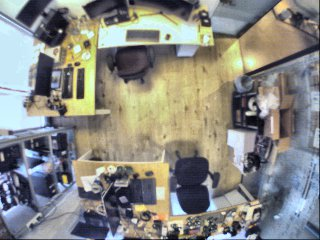

In [2]:
from IPython.display import Image
# Controlled environment as seen by the sensor.
Image(filename="ControlledENV/6000703-1221-012345-4040.jpg", width=420)

### Per-frame count accuracy across detection rates

*How often does a single frame's raw detection count already equal the
ground-truth room count, before any aggregation?*

Lower detection rates are simulated by **row-decimation** — keeping only every
*k*-th message the sensor actually sent (`k = period/10`: 1/20 → every 2nd,
1/30 → every 3rd, 1/60 → every 6th). This thins the **whole** stream uniformly,
dropping correct *and* wrong frames alike. That is why the per-frame accuracy
does not fall — and even ticks up slightly (86.4 % → 88.9 %): removing frames
also removes some of the wrong ones. It is a **sampling artifact of a shrinking
sample, not a genuine gain** in detection quality; fewer frames just give a
coarser, noisier estimate of the same ~86–89 % baseline.

Note this is the *raw per-frame* count with **no aggregation** — the baseline the
count pipeline builds on. It behaves very differently from the aggregated count
(§2), whose accuracy *does* depend on how densely detections arrive.


In [3]:
pf = pd.read_csv(f"{ART}/per_frame_accuracy.csv")
display(pf.rename(columns={
    "fps": "detection rate", "row_step": "every k-th frame",
    "frames": "frames", "correct": "correct", "pct_correct": "correct (%)"})
    [["detection rate", "every k-th frame", "frames", "correct", "correct (%)"]]
    .style.hide(axis="index").format({"correct (%)": "{:.1f}"})
    .background_gradient(subset=["correct (%)"], cmap="RdYlGn", vmin=60, vmax=100))

detection rate,every k-th frame,frames,correct,correct (%)
1/10,1,594,513,86.4
1/20,2,297,255,85.9
1/30,3,198,175,88.4
1/60,6,99,88,88.9


## 2. Experiment & methodology

**Design.** A 4×4 grid over the two periods, evaluated against ground truth:

- **Detection period** (input fps): **10, 20, 30, 60 s**. The native ~10 s stream
  is *row-decimated* — keep every *k*-th frame (`k = period/10`) — which
  preserves the real inter-report timing while simulating a slower sensor.
- **Count period** (output cadence): **30, 60, 90, 120 s**. The aggregator
  (median-3 + EMA-0.25 smoothing, whole-room AOI, matching the deployed gateway)
  emits a count at each period tick.

**Metric — exact-match accuracy.** Each configuration produces one reported
count per period tick. Every tick is matched to the ground-truth count in effect
at that time, and accuracy is the share of ticks whose reported count equals
ground truth exactly:

$$\text{Accuracy} = \frac{1}{N}\sum_{i=1}^{N}\mathbf{1}\!\left[\hat{y}_i = y_i\right]\times 100\%$$

where $N$ is the number of report ticks, $\hat{y}_i$ the reported count at tick
$i$, $y_i$ the ground-truth count at tick $i$, and $\mathbf{1}[\cdot]$ the
indicator (1 if the counts match, 0 otherwise).

*Toy example.* Ground truth $y = [0,\,1,\,2,\,2,\,1]$ and reported
$\hat{y} = [0,\,1,\,1,\,2,\,1]$ over $N=5$ ticks. Ticks 1, 2, 4, 5 match; tick 3
does not ($1 \neq 2$), so $\mathbf{1}[\cdot] = [1,1,0,1,1]$ and
$\text{Accuracy} = \tfrac{4}{5}\times 100\% = 80\%$.


In [4]:
res = pd.read_csv(f"{ART}/sweep/eval_results.csv")

print("Exact-match accuracy (%) — higher is better")
display(res.pivot(index="detection_period", columns="count_period", values="accuracy")
           .rename_axis("det ↓ / count →").style.format("{:.1f}")
           .background_gradient(cmap="RdYlGn", vmin=60, vmax=100))

Exact-match accuracy (%) — higher is better


count_period,30,60,90,120
det ↓ / count →,,,,
10,90.2,89.7,95.8,96.3
20,87.4,88.8,90.3,92.6
30,86.0,91.6,93.1,94.4
60,65.4,85.0,86.1,92.6


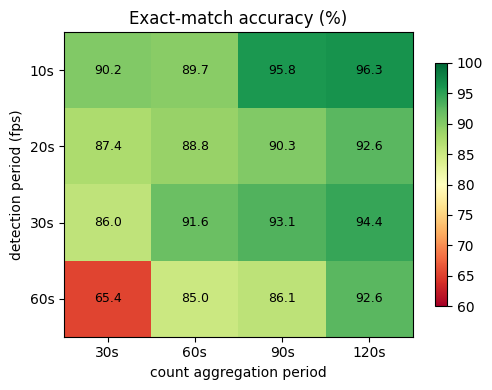

In [5]:
import matplotlib.pyplot as plt
%matplotlib inline

acc = res.pivot(index="detection_period", columns="count_period", values="accuracy")
fig, ax = plt.subplots(figsize=(5.2, 4))
im = ax.imshow(acc.values, cmap="RdYlGn", vmin=60, vmax=100, aspect="auto")
ax.set_xticks(range(len(acc.columns)), [f"{c}s" for c in acc.columns])
ax.set_yticks(range(len(acc.index)), [f"{i}s" for i in acc.index])
ax.set_xlabel("count aggregation period"); ax.set_ylabel("detection period (fps)")
ax.set_title("Exact-match accuracy (%)")
for i in range(acc.shape[0]):
    for j in range(acc.shape[1]):
        ax.text(j, i, f"{acc.values[i, j]:.1f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

### Aggregation uplift vs the per-frame baseline

How much does time-aggregation actually help over just trusting a single frame?
Each cell below is the **aggregated count accuracy minus the raw per-frame
accuracy at that detection rate** (from the table in §1). Positive (green) means
aggregation adds accuracy; negative (red) means it hurts. *Example:* at 1/10 fps
the per-frame baseline is 86.4 %; a 60 s count period reaches 89.7 %, so **+3.4**.

Reading **across each row** shows the main lever: a **longer counting period
lifts accuracy** — its wider smoothing window averages out noise and fills the
gaps a slow sensor leaves, turning even the badly-degraded 1/60 sensor from
−23.5 (30 s) into +3.7 (120 s).


In [6]:
baseline = pd.read_csv(f"{ART}/per_frame_accuracy.csv").set_index("detection_period_sec")["pct_correct"]
acc = res.pivot(index="detection_period", columns="count_period", values="accuracy")
uplift = acc.sub(baseline, axis=0).rename_axis("det ↓ / count →")

print("Count accuracy − per-frame baseline (pts) — green = aggregation helps")
display(uplift.style.format("{:+.1f}").background_gradient(cmap="RdYlGn", vmin=-10, vmax=10))

Count accuracy − per-frame baseline (pts) — green = aggregation helps


count_period,30,60,90,120
det ↓ / count →,,,,
10,+3.8,+3.4,+9.5,+9.9
20,+1.5,+2.9,+4.4,+6.7
30,-2.4,+3.2,+4.7,+6.1
60,-23.5,-3.8,-2.8,+3.7


## 3. Conclusions

- **Lower detection fps degrades accuracy**, but only mildly until it becomes
  sparse. At a fixed 60 s count period, accuracy falls from ~90 % (10 s) to
  85 % (60 s); the collapse appears only in the starved corner **60 s detection
  / 30 s count → 65 %**, where a 30 s window rarely contains a fresh detection.
- **A longer count period compensates for low fps.** Reading down any column, a
  bigger aggregation window recovers most of the loss: even the 60 s sensor
  reaches **92.6 %** at a 120 s count period. Smoothing over more time fills the
  gaps a slow sensor leaves.
- **Best trade-off:** dense input with a moderately long window — **10 s / 120 s
  → 96.3 %**. For a constrained low-fps sensor, pair it with the **longest
  affordable count period**.
- **Caveat:** longer count periods are scored on fewer, coarser ticks (214 at
  30 s → 54 at 120 s), so comparisons *down a column* (fps effect at fixed
  cadence) are cleaner than *across a row*.
